# Graph isolation and RF ablation

IEEE Latin America Transactions, manuscript ID 11172.

Computes physical-graph isolation at 30 m and a random-forest ablation
that removes OPEN/WEP indicators, using only columns in
`data/datos_wifi_curated_anon.parquet`.

PhysAgg-R multi-seed tables are in `03_reproduce_physagg.ipynb`.


In [1]:
from __future__ import annotations

from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score

ROOT = Path("..").resolve() if Path.cwd().name == "notebooks" else Path(".").resolve()
DATA = ROOT / "data" / "datos_wifi_curated_anon.parquet"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
FIG_REL = FIG.relative_to(ROOT).as_posix()

df = pd.read_parquet(DATA)
print(
    f"Loaded {DATA.relative_to(ROOT).as_posix()} | "
    f"rows={len(df):,} | APs={df['bssid'].nunique():,}"
)
print("Figure directory:", FIG_REL)

Loaded data/datos_wifi_curated_anon.parquet | rows=53,371 | APs=36,010
Figure directory: reports/figures


## Physical-graph isolation at 30 m

,min_co_observations,isolate_pct
0,1,8.2
1,2,85.1
2,3,95.2


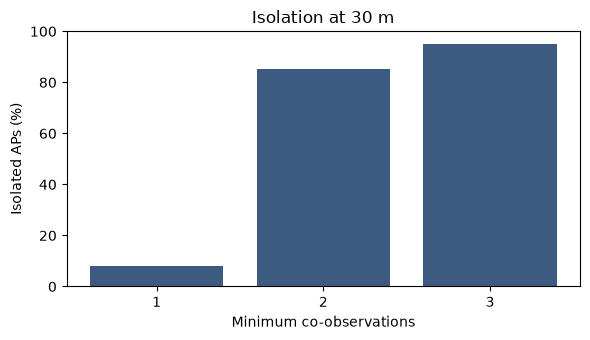

Saved: reports/figures/isolation_sensitivity.png


In [2]:
def isolate_fraction(frame: pd.DataFrame, nearby_m: float = 30.0, min_co_obs: int = 2) -> float:
    """Fraction of APs with no edge after co-observation filtering."""
    edge_acc: dict[tuple[str, str], int] = defaultdict(int)
    for _, scan in frame.groupby(["device_id", "timestamp"], sort=False):
        sub = scan.dropna(subset=["bssid", "estimated_distance"])
        if len(sub) < 2:
            continue
        rec = sub[["bssid", "estimated_distance"]].to_dict("records")
        for i, a in enumerate(rec):
            for b in rec[i + 1 :]:
                d_avg = 0.5 * (a["estimated_distance"] + b["estimated_distance"])
                if d_avg <= nearby_m:
                    edge_acc[tuple(sorted((a["bssid"], b["bssid"])))] += 1
    connected: set[str] = set()
    for (u, v), c in edge_acc.items():
        if c >= min_co_obs:
            connected.add(u)
            connected.add(v)
    n_ap = int(frame["bssid"].nunique())
    return 100.0 * (n_ap - len(connected)) / max(n_ap, 1)

sens = {
    min_co: round(isolate_fraction(df, nearby_m=30.0, min_co_obs=min_co), 1)
    for min_co in (1, 2, 3)
}
sens_df = pd.DataFrame(
    [{"min_co_observations": k, "isolate_pct": v} for k, v in sens.items()]
)
display(sens_df)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar([str(k) for k in sens], list(sens.values()), color="#3d5a80")
ax.set_xlabel("Minimum co-observations")
ax.set_ylabel("Isolated APs (%)")
ax.set_title("Isolation at 30 m")
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(FIG / "isolation_sensitivity.png")
plt.show()
print("Saved:", f"{FIG_REL}/isolation_sensitivity.png")

## RF ablation on public columns (OPEN/WEP proxies)

Temporal hold-out by observation timestamp (last 20% test). Features are only
those shipped in the anonymised parquet.

In [3]:
work = df.copy()
sec = work["security_type_parsed"].astype(str).str.upper()
work["is_open"] = sec.eq("OPEN").astype(float)
work["is_wep"] = sec.eq("WEP").astype(float)
work["is_randomized_mac"] = work["is_randomized_mac"].astype(float)

base_feats = [
    "level", "frequency", "channel", "bandwidth",
    "estimated_distance", "distance_residual", "is_randomized_mac",
]
proxy_feats = ["is_open", "is_wep"]
y = work["is_anomaly_heuristic"].astype(int).to_numpy()

cut = work["timestamp"].quantile(0.8)
train_m = work["timestamp"] <= cut
test_m = ~train_m

def pr_auc(feature_cols: list[str]) -> float:
    X = work[feature_cols].astype(float).to_numpy()
    clf = RandomForestClassifier(
        n_estimators=200, max_depth=12, random_state=42, n_jobs=-1, class_weight="balanced"
    )
    clf.fit(X[train_m.to_numpy()], y[train_m.to_numpy()])
    scores = clf.predict_proba(X[test_m.to_numpy()])[:, 1]
    return float(average_precision_score(y[test_m.to_numpy()], scores))

pr_full = pr_auc(base_feats + proxy_feats)
pr_reduced = pr_auc(base_feats)
rf_df = pd.DataFrame([
    {
        "feature_set": "with OPEN/WEP proxies",
        "n_features": len(base_feats) + len(proxy_feats),
        "pr_auc": round(pr_full, 3),
    },
    {
        "feature_set": "without OPEN/WEP proxies",
        "n_features": len(base_feats),
        "pr_auc": round(pr_reduced, 3),
    },
])
rf_df["delta"] = rf_df["pr_auc"] - rf_df.loc[0, "pr_auc"]
display(rf_df)


,feature_set,n_features,pr_auc,delta
0,with OPEN/WEP proxies,9,0.699,0.000
1,without OPEN/WEP proxies,7,0.333,-0.366


## Corpus snapshot used by the paper protocol

In [4]:
snap = pd.DataFrame([
    {"quantity": "rows", "value": len(df)},
    {"quantity": "unique_bssid", "value": int(df["bssid"].nunique())},
    {"quantity": "unique_device_id", "value": int(df["device_id"].nunique())},
    {"quantity": "municipalities", "value": int(df["municipality"].nunique())},
    {"quantity": "heuristic_positive_rate", "value": round(float(df["is_anomaly_heuristic"].mean()), 4)},
    {"quantity": "isolate_pct_min_coobs_2", "value": sens[2]},
])
display(snap)
print("Saved figures under:", FIG_REL)

,quantity,value
0,rows,53371.0000
1,unique_bssid,36010.0000
2,unique_device_id,27.0000
3,municipalities,45.0000
4,heuristic_positive_rate,0.2173
5,isolate_pct_min_coobs_2,85.1000


Saved figures under: reports/figures
